# Ex08


Tự viết toàn bộ code. File này không có lời giải.

Làm lần lượt sáu phần:

1. Mã hóa (LabelEncoder và OneHotEncoder)
2. Ghép thành một bảng số duy nhất (concat)
3. Chuẩn hóa (StandardScaler hoặc MinMaxScaler)
4. Đưa bảng đã chuẩn hóa vào KMeans để gom cụm
5. Elbow để xem k
6. KNN để dự đoán Response

Dữ liệu: data/marketing_campaign.csv, dấu phân tách là tab.

Dùng đúng các cột sau, không thêm cột khác vào bảng đưa vào mô hình:

| Cột | Việc phải làm |
|---|---|
| Education | LabelEncoder |
| Marital_Status | OneHotEncoder |
| Income, Recency, MntWines, MntMeatProducts | giữ nguyên, vì đã là số |

Bỏ các dòng thiếu Income trước khi mã hóa. Không đưa Response vào bảng đặc trưng. Response chỉ dùng làm nhãn ở phần KNN.

random_state=0. Với KMeans đặt thêm n_init=10.


## 1. Mã hóa

Education và Marital_Status là chữ. KMeans không nhận chữ.

In classes_ của LabelEncoder sau khi fit. In tên cột do OneHotEncoder sinh ra.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Đọc dữ liệu (phân tách bằng tab) và bỏ các dòng thiếu Income TRƯỚC khi mã hóa
df = pd.read_csv("data/marketing_campaign.csv", sep="\t")
print("Trước khi bỏ dòng thiếu Income:", df.shape)
df = df.dropna(subset=["Income"]).reset_index(drop=True)
print("Sau khi bỏ dòng thiếu Income :", df.shape)

# Education -> LabelEncoder (1 cột số nguyên)
le = LabelEncoder()
edu_code = le.fit_transform(df["Education"])
print("\nclasses_ của LabelEncoder:", le.classes_)

# Marital_Status -> OneHotEncoder (mỗi nhóm một cột 0/1)
ohe = OneHotEncoder(sparse_output=False)
ms_onehot = ohe.fit_transform(df[["Marital_Status"]])
ms_cols = ohe.get_feature_names_out(["Marital_Status"])
print("\nTên cột do OneHotEncoder sinh ra:")
print(list(ms_cols))


Trước khi bỏ dòng thiếu Income: (2240, 29)
Sau khi bỏ dòng thiếu Income : (2216, 29)

classes_ của LabelEncoder: ['2n Cycle' 'Basic' 'Graduation' 'Master' 'PhD']

Tên cột do OneHotEncoder sinh ra:
['Marital_Status_Absurd', 'Marital_Status_Alone', 'Marital_Status_Divorced', 'Marital_Status_Married', 'Marital_Status_Single', 'Marital_Status_Together', 'Marital_Status_Widow', 'Marital_Status_YOLO']


**Trả lời, không cần code.**

1. LabelEncoder xếp Education theo thứ tự nào? Thứ tự đó có phải Basic, rồi 2n Cycle, Graduation, Master, PhD hay không?

   **Đáp:** Không. LabelEncoder xếp theo thứ tự bảng chữ cái của chuỗi: `classes_` = ['2n Cycle', 'Basic', 'Graduation', 'Master', 'PhD'], tức mã 2n Cycle = 0, Basic = 1, Graduation = 2, Master = 3, PhD = 4. Vì vậy 2n Cycle (thường được hiểu là bậc ngang Master) lại nằm thấp nhất, thấp hơn cả Basic. Đây là thứ tự chữ cái chứ không phải thứ tự trình độ học vấn; chỉ có đoạn Graduation < Master < PhD là trùng hợp.

2. Vì sao Marital_Status dùng OneHotEncoder còn Education lại dùng LabelEncoder trong bài này?

   **Đáp:** Marital_Status là biến định danh, các nhóm Married, Single, Divorced... không có thứ hạng. Nếu mã thành số nguyên thì KMeans và KNN, vốn dựa trên khoảng cách, sẽ hiểu có "xa gần" giữa các nhóm (ví dụ Single = 4 gần Together = 5 hơn Divorced = 2), điều này vô nghĩa. One-hot làm các nhóm cách đều nhau. Education thì có thứ bậc tự nhiên (Basic < Graduation < Master < PhD), nên dùng một cột số nguyên là chấp nhận được và giữ bảng gọn (1 cột thay vì 5). Tuy nhiên như câu 1 cho thấy, LabelEncoder chỉ xếp theo chữ cái nên chưa đúng thứ bậc; muốn chuẩn hơn thì dùng OrdinalEncoder với thứ tự chỉ định rõ.


## 2. Ghép thành một bảng số duy nhất

Ghép ba khối theo cột: số của Education, các cột biến giả của Marital_Status, và bốn cột số. Kết quả là một DataFrame, mọi cột đều là số, số dòng bằng số dòng sau khi bỏ Income thiếu.

In shape và columns.


In [2]:
# Ba khối: Education (số), Marital_Status (biến giả), bốn cột số giữ nguyên
edu_df = pd.DataFrame({"Education": edu_code}, index=df.index)
ms_df = pd.DataFrame(ms_onehot, columns=ms_cols, index=df.index)
num_df = df[["Income", "Recency", "MntWines", "MntMeatProducts"]]

X = pd.concat([edu_df, ms_df, num_df], axis=1)

print("shape  :", X.shape)
print("columns:", list(X.columns))
print("Số ô thiếu:", int(X.isna().sum().sum()), "| kiểu dữ liệu:", X.dtypes.unique())


shape  : (2216, 13)
columns: ['Education', 'Marital_Status_Absurd', 'Marital_Status_Alone', 'Marital_Status_Divorced', 'Marital_Status_Married', 'Marital_Status_Single', 'Marital_Status_Together', 'Marital_Status_Widow', 'Marital_Status_YOLO', 'Income', 'Recency', 'MntWines', 'MntMeatProducts']
Số ô thiếu: 0 | kiểu dữ liệu: [dtype('int64') dtype('float64')]


**Trả lời.**

3. Bảng ghép có bao nhiêu dòng, bao nhiêu cột? Kể tên các cột biến giả.

   **Đáp:** 2216 dòng (2240 dòng gốc trừ 24 dòng thiếu Income) và 13 cột: 1 cột Education + 8 cột biến giả + 4 cột số. Tám cột biến giả là `Marital_Status_Absurd`, `Marital_Status_Alone`, `Marital_Status_Divorced`, `Marital_Status_Married`, `Marital_Status_Single`, `Marital_Status_Together`, `Marital_Status_Widow`, `Marital_Status_YOLO`.


## 3. Chuẩn hóa

Chọn một trong hai: StandardScaler hoặc MinMaxScaler. Fit trên toàn bộ bảng vừa ghép. In trung bình mỗi cột sau khi scale, làm tròn 3 chữ số.


In [3]:
# StandardScaler, fit trên toàn bộ bảng X vừa ghép
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)

print("Trung bình mỗi cột sau khi scale (làm tròn 3 chữ số):")
print(X_scaled.mean().round(3) + 0.0)  # +0.0 để không hiện -0.0


Trung bình mỗi cột sau khi scale (làm tròn 3 chữ số):
Education                  0.0
Marital_Status_Absurd      0.0
Marital_Status_Alone       0.0
Marital_Status_Divorced    0.0
Marital_Status_Married     0.0
Marital_Status_Single      0.0
Marital_Status_Together    0.0
Marital_Status_Widow       0.0
Marital_Status_YOLO        0.0
Income                     0.0
Recency                    0.0
MntWines                   0.0
MntMeatProducts            0.0
dtype: float64


**Trả lời.**

4. Bạn chọn scaler nào? Income và MntWines sẽ chi phối khoảng cách thế nào nếu bỏ bước này?

   **Đáp:** Mình chọn StandardScaler (mỗi cột về trung bình 0, độ lệch chuẩn 1) vì KMeans và KNN đều dùng khoảng cách Euclid. Nếu bỏ bước này, Income dao động từ 1.730 đến 666.666 (độ lệch chuẩn khoảng 25.173) và MntWines từ 0 đến 1.493 (khoảng 337), trong khi Recency chỉ 0 đến 99, Education 0 đến 4 và các biến giả chỉ 0 hoặc 1. Bình phương khoảng cách khi đó gần như do Income quyết định, MntWines đứng thứ hai, các cột còn lại hầu như không có tiếng nói, nên cụm thực chất chỉ chia theo thu nhập. Lưu ý thêm: StandardScaler cũng có điểm yếu ở dữ liệu này, các nhóm hiếm như YOLO và Absurd (mỗi nhóm 2 dòng) có z-score khoảng 33, và dòng Income = 666.666 có z-score khoảng 24.


## 4. K-Means

n_clusters=3. In số dòng mỗi cụm và trung bình Income, Recency, MntWines, MntMeatProducts theo cụm. Trung bình tính trên giá trị gốc, không tính trên bảng đã scale.


In [4]:
km = KMeans(n_clusters=3, random_state=0, n_init=10)
labels = km.fit_predict(X_scaled)

# Trung bình tính trên GIÁ TRỊ GỐC (không phải bảng đã scale)
profile_cols = ["Income", "Recency", "MntWines", "MntMeatProducts"]
result = df[profile_cols].copy()
result["cluster"] = labels

print("Số dòng mỗi cụm:")
print(result["cluster"].value_counts().sort_index())

print("\nTrung bình theo cụm (giá trị gốc):")
print(result.groupby("cluster")[profile_cols].mean().round(1))

# Kiểm tra thêm để đọc cụm ở câu 5: cụm nằm ở nhóm Marital_Status nào
print("\nSố dòng theo Marital_Status x cụm:")
print(pd.crosstab(df["Marital_Status"], labels, colnames=["cluster"]))


Số dòng mỗi cụm:
cluster
0    549
1    857
2    810
Name: count, dtype: int64

Trung bình theo cụm (giá trị gốc):
          Income  Recency  MntWines  MntMeatProducts
cluster                                             
0        51832.7     49.2     302.1            185.4
1        51725.0     48.3     299.9            160.9
2        53080.8     49.7     312.7            161.0

Số dòng theo Marital_Status x cụm:
cluster           0    1    2
Marital_Status               
Absurd            2    0    0
Alone             0    0    3
Divorced          0    0  232
Married           0  857    0
Single          471    0    0
Together          0    0  573
Widow            76    0    0
YOLO              0    0    2


**Trả lời.**

5. Ba cụm khác nhau ở mức chi tiêu nào? Gọi tên mỗi cụm bằng chữ, không bằng id 0, 1, 2.

   **Đáp:** Thực tế ba cụm gần như không khác nhau về chi tiêu: Income trung bình chỉ dao động 51,7 đến 53,1 nghìn, Recency 48 đến 50 ngày, MntWines 300 đến 313, MntMeatProducts 161 đến 185 (cụm 0 nhỉnh hơn khoảng 15%, vẫn nhỏ so với độ lệch chuẩn 224). Bảng chéo với Marital_Status cho thấy các cụm được tạo ra gần như hoàn toàn bởi tình trạng hôn nhân, nên mình gọi tên theo đó: cụm 0 (549 dòng) là "nhóm độc thân/góa" (Single, Widow cùng 2 dòng Absurd), cụm 1 (857 dòng) là "nhóm đã kết hôn" (toàn bộ Married), cụm 2 (810 dòng) là "nhóm sống chung/ly hôn" (Together, Divorced cùng Alone và YOLO). Nguyên nhân là sau khi scale, mỗi cột đều có phương sai 1, trong khi 9 trên 13 cột là Education và biến giả, còn chi tiêu chỉ chiếm 2 cột, nên khoảng cách bị tình trạng hôn nhân chi phối. Muốn cụm phản ánh chi tiêu thì nên gom cụm chỉ trên các cột số và gộp hoặc bỏ các nhóm hiếm.

6. Đổi random_state thì id cụm có thể đảo. Cách đọc ở câu 5 còn đúng không?

   **Đáp:** Còn đúng, vì ở câu 5 cụm được gọi tên theo nội dung (nhóm hôn nhân và các giá trị trung bình), không theo id. Id 0, 1, 2 chỉ là nhãn tùy ý nên có thể hoán đổi giữa các lần chạy. Điều cần tránh là ghi cứng kiểu "cụm 0 = độc thân"; mỗi lần chạy lại thì phải đọc lại bảng trung bình và bảng chéo. Với n_init = 10, phân hoạch thường khá ổn định, nhưng vẫn nên kiểm tra khi đổi random_state.


## 5. Elbow

Dùng đúng bảng đã chuẩn hóa ở phần 3. Thử k từ 1 đến 8. Với mỗi k, lưu inertia. Vẽ inertia theo k, trục hoành là k, trục tung là inertia.


 k  inertia  giam_so_voi_k_truoc
 1  28808.0                  NaN
 2  25276.3              -3531.7
 3  22722.7              -2553.6
 4  20107.0              -2615.6
 5  17726.2              -2380.8
 6  15648.5              -2077.7
 7  13275.0              -2373.5
 8  11738.7              -1536.3

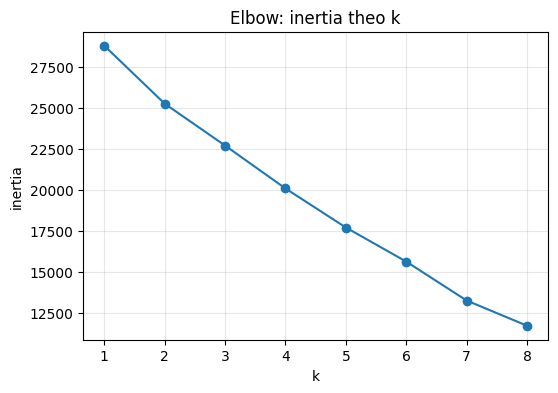

In [5]:
ks = list(range(1, 9))
inertias = []
for k in ks:
    km_k = KMeans(n_clusters=k, random_state=0, n_init=10).fit(X_scaled)
    inertias.append(km_k.inertia_)

elbow = pd.DataFrame({"k": ks, "inertia": inertias})
elbow["giam_so_voi_k_truoc"] = elbow["inertia"].diff()
print(elbow.round(1).to_string(index=False))

plt.figure(figsize=(6, 4))
plt.plot(ks, inertias, marker="o")
plt.xlabel("k")
plt.ylabel("inertia")
plt.title("Elbow: inertia theo k")
plt.xticks(ks)
plt.grid(alpha=0.3)
plt.show()


**Trả lời.**

7. Inertia nhỏ nhất trong bảng nằm ở k nào? Vì sao không chọn k đó làm số cụm?

   **Đáp:** Nhỏ nhất ở k = 8 (khoảng 11.738,7). Inertia luôn giảm khi k tăng (đến mức k bằng số dòng thì inertia bằng 0), nên giá trị nhỏ nhất không có nghĩa là tốt nhất. Chọn k lớn nhất chỉ là chia nhỏ dữ liệu quá mức, cụm khó diễn giải và không có ý nghĩa cho marketing. Điều cần tìm là điểm mà tăng thêm k không còn làm inertia giảm đáng kể.

8. Nhìn chỗ đường gãy, bạn chọn k nào cho phòng marketing? Có trùng k = 3 ở phần 4 không?

   **Đáp:** Đường cong ở đây gần như thẳng, không có khuỷu rõ ràng. Mức giảm sau mỗi bước lần lượt là 3.532 (k 1 sang 2), 2.554, 2.616, 2.381, 2.078, 2.374 và 1.536. Chỉ có độ gãy nhẹ ở k = 2 sang 3 (bước giảm đầu lớn nhất, sau đó đều quanh 2.400), nên mình chọn k = 3, trùng với phần 4, nhưng bằng chứng yếu. Nên kiểm tra thêm bằng silhouette, và nhớ rằng các cụm hiện tại chủ yếu phản ánh tình trạng hôn nhân chứ chưa phải hành vi chi tiêu.


## 6. KNN

KNN không gom cụm. KNN cần nhãn. Nhãn là Response. Bảng đặc trưng là bảng đã ghép ở phần 2, bản chưa chuẩn hóa.

Chia train/test, test_size=0.2, random_state=0, stratify theo Response.

Tạo một scaler mới, cùng loại với phần 3. Fit scaler chỉ trên tập train, rồi transform tập test. Không dùng lại scaler đã fit trên toàn bộ dữ liệu ở phần 3.

Thử n_neighbors trong 1, 3, 5, 7, 11, 21. Với mỗi k in accuracy và F1 của lớp 1. Chọn một k và in classification_report của k đó.


In [6]:
# Nhãn là Response; đặc trưng là bảng X (bản CHƯA chuẩn hóa) ở phần 2
y = df["Response"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0, stratify=y
)
print("Tỉ lệ Response=1 - toàn bộ / train / test:",
      round(y.mean(), 4), round(y_train.mean(), 4), round(y_test.mean(), 4))

# Scaler MỚI, cùng loại: fit chỉ trên train, chỉ transform test
knn_scaler = StandardScaler()
X_train_s = knn_scaler.fit_transform(X_train)
X_test_s = knn_scaler.transform(X_test)

rows = []
for k in [1, 3, 5, 7, 11, 21]:
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_train_s, y_train)
    pred = knn.predict(X_test_s)
    rows.append({
        "k": k,
        "accuracy": accuracy_score(y_test, pred),
        "F1_lop_1": f1_score(y_test, pred, pos_label=1),
    })
print()
print(pd.DataFrame(rows).round(4).to_string(index=False))

# Mốc so sánh: luôn đoán Response = 0
print("\nAccuracy nếu luôn đoán 0:", round((y_test == 0).mean(), 4))

# Chọn k = 7 và in classification_report
best_k = 7
knn = KNeighborsClassifier(n_neighbors=best_k).fit(X_train_s, y_train)
pred = knn.predict(X_test_s)
print(f"\nclassification_report với k = {best_k}:")
print(classification_report(y_test, pred, digits=3))


Tỉ lệ Response=1 - toàn bộ / train / test: 0.1503 0.1501 0.1509



 k  accuracy  F1_lop_1
 1    0.8153    0.3051
 3    0.8378    0.2800
 5    0.8491    0.2947
 7    0.8604    0.2955
11    0.8671    0.2532
21    0.8604    0.1622

Accuracy nếu luôn đoán 0: 0.8491

classification_report với k = 7:
              precision    recall  f1-score   support

           0      0.872     0.979     0.922       377
           1      0.619     0.194     0.295        67

    accuracy                          0.860       444
   macro avg      0.746     0.586     0.609       444
weighted avg      0.834     0.860     0.828       444



**Trả lời.**

9. stratify theo Response giữ điều gì giữa train và test?

   **Đáp:** Giữ nguyên tỉ lệ các lớp của Response. Response = 1 chiếm khoảng 15% ở toàn bộ dữ liệu (0,1503), ở train (0,1501) và ở test (0,1509). Nếu không stratify, tập test chỉ có khoảng 67 mẫu lớp 1 nên tỉ lệ có thể lệch ngẫu nhiên, làm F1 lớp 1 dao động và khó so sánh giữa các k.

10. Fit scaler trên cả bảng rồi mới chia train/test thì sai ở đâu?

    **Đáp:** Đó là rò rỉ dữ liệu (data leakage): trung bình và độ lệch chuẩn tính từ cả tập test, nên bước tiền xử lý đã "nhìn thấy" dữ liệu mà lẽ ra mô hình chưa biết. Điểm trên test vì thế bị lạc quan hơn thực tế. Khi triển khai, khách hàng mới chưa có mặt lúc fit scaler, nên cách đúng là fit trên train rồi chỉ transform test, như đã làm ở phần 6.

11. k bạn chọn là bao nhiêu? Accuracy cao hơn F1 lớp 1 thì đọc thêm chỉ số nào trước khi kết luận mô hình tốt?

    **Đáp:** Mình chọn k = 7: accuracy 0,860 và F1 lớp 1 khoảng 0,296. F1 ở k = 7 gần mức cao nhất (k = 1 nhỉnh hơn một chút, 0,305, nhưng k = 1 nhạy nhiễu và accuracy chỉ 0,815), còn từ k = 11 trở lên recall tụt nên F1 giảm còn 0,253 và 0,162. Cần chú ý là chọn k bằng cách nhìn tập test thì kết quả hơi lạc quan; chặt chẽ hơn nên dùng cross-validation trên train. Khi accuracy cao hơn hẳn F1 lớp 1, phải đọc thêm precision và recall của lớp 1, và so với mốc luôn đoán 0 (accuracy 0,849). Ở k = 7, precision lớp 1 là 0,619 nhưng recall chỉ 0,194, tức mô hình bắt được 13 trên 67 khách có phản hồi. Accuracy chỉ hơn mốc đoán toàn 0 khoảng 1,1 điểm phần trăm, vì lớp 0 chiếm 85%, nên chưa thể kết luận mô hình tốt.
